<!-- cabecera-entorno -->
## Antes de empezar

**Clase 8 · Principios de visualización** — Bloque 3 · Reto. Este cuaderno lo recorre **usted solo**,
leyendo: cada tarea trae la explicación y los comandos que necesita. El profesor circula por el salón
resolviendo dudas. Es el entregable de la clase.

**La rutina de siempre:** `git pull` antes de clase, y el entorno virtual activo (`(.venv)` en la
terminal). El archivo que se descarga se llama `reto.ipynb`; **al entregar se renombra a
`reto_clase08_APELLIDO.ipynb`**, que es el nombre que pide el cierre. Si va a modificar este archivo,
trabaje sobre una copia: duplique `reto.ipynb` como
`reto_mio.ipynb` y edite el duplicado. Así `git pull` nunca le reclama.

**Si la celda de abajo falla, no siga:** la respuesta está en el manual del entorno,
[`../INSTALACION.md`](../INSTALACION.md).

| Si ve esto | Qué pasó | Dónde se arregla |
|------------|----------|------------------|
| `ModuleNotFoundError` | El entorno virtual no está activo, o VSCode eligió otro intérprete | Manual, secciones 6.3 y 8.4, y problema 5 |
| `FileNotFoundError` al leer el CSV | El notebook se abrió desde otra carpeta, o falta hacer `git pull` | Manual, problema 6 |
| El kernel no aparece en VSCode | Falta la extensión Jupyter o `ipykernel` dentro del entorno | Manual, problema 4 |

In [1]:
# Verificación del entorno. Si algo falla aquí, la solución está en ../INSTALACION.md
import sys
from pathlib import Path

try:
    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
    import seaborn as sns
except ModuleNotFoundError as error:
    raise ModuleNotFoundError(
        f"Falta la librería '{error.name}'. Active el entorno virtual y seleccione el intérprete "
        ".venv en VSCode (Ctrl+Shift+P > Python: Select Interpreter), luego reinicie el kernel. "
        "Ver ../INSTALACION.md, problema 5."
    ) from error

print("Intérprete:", sys.executable)
if ".venv" not in sys.executable:
    print("AVISO: este no parece el Python del entorno virtual. En VSCode: Ctrl+Shift+P >",
          "'Python: Select Interpreter' > el que dice .venv, y reinicie el kernel.")

RUTA_VERIFICACION = "../datos/EJECUCION_PRESUPUESTAL.csv"
if Path(RUTA_VERIFICACION).exists():
    print("Datos: encontrados en", RUTA_VERIFICACION)
else:
    print("FALTA el archivo", RUTA_VERIFICACION, "- abra en VSCode la carpeta raíz del curso",
          "y ejecute 'git pull'. Ver ../INSTALACION.md, problema 6.")

Intérprete: /home/breiner/Development/data_analysis/analitica-datos-estudiantes/.venv/bin/python
Datos: encontrados en ../datos/EJECUCION_PRESUPUESTAL.csv


# Clase 8 · Reto — Cinco figuras publication-ready sobre ejecución presupuestal

**Equipo:** Breiner Martínez

**Fecha:** 15 de octubre de 2026

**Dataset:** `../datos/EJECUCION_PRESUPUESTAL.csv` — ejecución del Presupuesto General de la
Nación, vía datos.gov.co.
**Consigna completa:** `reto.md`

3.645 filas x 21 columnas. Una fila = un rubro presupuestal de una entidad, con su fuente de
financiación.

## Sí, es el mismo dataset del demo. Es a propósito

En el resto del curso el reto usa datos que no vio en el demo. **Esta clase es la excepción
declarada.**

Hoy lo que se evalúa no es su capacidad de cargar y entender datos nuevos: es su **criterio visual**.
Si tuviera que aprenderse un dataset nuevo, gastaría 20 de sus 60 minutos en limpieza y llegaría a
los gráficos con 40.

**Lo que cambia no son los datos: son los gráficos.** Cuatro de las cinco figuras son de tipos que no
aparecieron en el demo: barras agrupadas, gráfico de dispersión, apiladas al 100% y small multiples.

> Los mismos números, cinco preguntas distintas, cinco gráficos distintos. Si el gráfico correcto
> dependiera de los datos, esto sería trivial. Depende de la pregunta.

### Las columnas que va a usar

| Columna | Qué es |
|---------|--------|
| `Nombre Sector` | 32 sectores. El nivel grueso |
| `Nombre Entidad` | 221 entidades. El nivel fino |
| `Nombre Nivel Uno Rubro` | Tres categorías: funcionamiento, inversión y servicio de la deuda |
| `Apropiación Vigente` | Lo que le autorizaron gastar. El techo |
| `Compromisos` | Lo que ya comprometió en contratos firmados |
| `Obligaciones` | Lo que ya recibió y debe pagar |
| `Pagos` | Lo que efectivamente salió |

El **porcentaje de ejecución** es `Compromisos / Apropiación Vigente * 100`.

## Cómo se recorre este cuaderno

Usted trabaja solo. Nadie va a dictar los pasos desde el tablero, así que cada tarea trae todo lo que
necesita para resolverse leyendo:

| Parte de la tarea | Qué contiene |
|-------------------|--------------|
| **La pregunta** | Lo que hay que responder, escrito en español |
| **El concepto** | Qué técnica aplica y por qué esa y no otra |
| **Los comandos** | Las instrucciones exactas que va a usar, escritas de forma genérica |
| **Lo que decide usted** | Qué columna, qué recorte, qué color, qué título. Ahí no hay respuesta escrita |
| **La celda de código** | Los pasos numerados en comentarios. Usted escribe las líneas |
| **La comprobación** | `comprobar('TN', ...)` le dice si el resultado es el correcto, sin mostrárselo |

**Las cajas "Para entender qué está pasando"**, igual que en el demo, explican la **mecánica** de las
construcciones que hoy escribe por primera vez: las barras agrupadas de la tarea 4, la escala
logarítmica y la anotación con flecha de la tarea 5, el acumulador de la tarea 7 y el arreglo de ejes
de la tarea 8. **Son saltables:** si la construcción ya se le entiende, siga de largo. Si se atascó,
la explicación está ahí y no hay que buscarla en otro archivo.

**Las diez tareas (T1 a T10)** están repartidas en tres partes:

| Parte | Tareas | De qué va |
|-------|--------|-----------|
| **A · Los datos** | T1, T2 | Las dos tablas agregadas de las que salen las cinco figuras |
| **B · Las cinco figuras** | T3 a T8 | Una tarea por figura, más la tabla normalizada de la figura 4 |
| **C · Sin el orden** | T9, T10 | El ensamblaje y la exportación. **La que más pesa** |

**Por qué esto sigue siendo un reto y no una copia.** Los comandos se dan; las decisiones no. Usted
elige el recorte, el color, el orden, la unidad del eje y —sobre todo— **el título, que tiene que
decir una conclusión y ser verdadero**. Eso es lo que se evalúa. Las celdas `comprobar(...)` comparan
una huella digital de su resultado con la esperada: nunca revelan la respuesta.

**Las tareas de gráfico se comprueban distinto.** No hay una única figura correcta, así que lo que se
revisa es lo verificable: que esté dibujada, titulada, con los ejes etiquetados, con el eje en cero
donde la regla lo exige, con la línea de referencia donde hace falta y con la misma escala en todos
los paneles. Los puntos 1, 7 y 8 de la checklist —los cinco segundos, la escala de grises y que el
título sea **verdadero**— no los puede revisar ningún programa. Esos los juzga usted, y son los que
más pesan al calificar.

**El reparto del tiempo:** unos 9 minutos por figura. Si se demora 20 en la primera, no termina. La
figura 1 es la del demo: hágala rápido, es el calentamiento.

### El bucle de la clase 3, sobre una figura

Cada figura es **una vuelta completa** del bucle que ya conoce, no una sola. Las cuatro skills están
instaladas desde la clase 3 y hoy se usan; no se vuelven a explicar.

| Tramo | Skill | Qué escribe hoy, y cuándo |
|-------|-------|---------------------------|
| Especificar | `especifica-encargo` | La pregunta que la figura responde, quién la mira y **el título que espera poder escribir al final**. Antes de dibujar |
| Planear | `planea-trabajo` | El tipo de gráfico y por qué ese y no el vecino, el recorte, la unidad del eje, qué se resalta |
| Ejecutar | `ejecuta-plan` | La figura. Es el único tramo que se delega entero |
| Validar | `valida-resultado` | El título contra la tabla, condición por condición |

**Por qué importa hoy más que en otras clases.** Un gráfico bonito que no responde nada casi siempre
salió de un encargo que no preguntaba nada. Si el título se escribe **después** de ver la figura, el
título va a describir la figura; si se escribe **antes**, la figura tiene que ganárselo. Ese cambio
de orden es todo el tramo de especificar.

**Y la mitad que se olvida:** si al validar el título resulta falso, **no se parcha el título**. Se
vuelve a especificar, porque el problema estaba en la pregunta.

---

## Paso 0 · Preparación

Las tres celdas de abajo ya están escritas: las librerías, la carga y la limpieza mínima. Ejecútelas
y **lea lo que imprimen**.

**Qué se limpia y por qué.** Solo dos cosas, que son las que impiden graficar bien:

1. El **espacio no separable** (`\xa0`), que parte una categoría en dos que se ven idénticas.
   `str.strip()` no lo arregla, porque no está en los extremos.
2. Las **tres filas con apropiación en cero**, que al calcular el porcentaje de ejecución dividen
   por cero y producen `NaN` o `inf` sin lanzar ningún error.

`Nombre Sector` y `Nombre Entidad` ya están limpios. No gaste tiempo ahí.

In [2]:
import os
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 200)

# La carpeta donde van a quedar los PNG exportados
os.makedirs('figuras', exist_ok=True)

print('pandas', pd.__version__, '| matplotlib', plt.matplotlib.__version__)

pandas 3.0.6 | matplotlib 3.11.2


In [3]:
# La ruta se lee desde la carpeta de este cuaderno: cada ../ sube un nivel.
df = pd.read_csv('../datos/EJECUCION_PRESUPUESTAL.csv')

df_limpio = df.copy()

# 1. El espacio no separable, en todas las columnas de texto
for col in df_limpio.columns:
    if pd.api.types.is_string_dtype(df_limpio[col]):
        df_limpio[col] = df_limpio[col].str.replace('\xa0', ' ', regex=False).str.strip()

# 2. Las filas sin apropiación. Se filtran y se dice cuántas: nunca en silencio.
excluidas = (df_limpio['Apropiación Vigente'] == 0).sum()
df_limpio = df_limpio[df_limpio['Apropiación Vigente'] > 0].copy()

print(f'Filas cargadas: {len(df)}')
print(f'Filas excluidas por apropiación en cero: {excluidas}')
print(f'Filas de trabajo: {len(df_limpio)}')
print(f'Sectores: {df_limpio["Nombre Sector"].nunique()} | '
      f'Entidades: {df_limpio["Nombre Entidad"].nunique()}')

# La referencia nacional: se usa en las figuras 3 y 5, y en la tarea 9.
# Es la suma sobre la suma, no el promedio de los porcentajes: responde
# "cuanto del presupuesto del pais esta comprometido", que es otra pregunta.
ejecucion_nacional = (df_limpio['Compromisos'].sum() /
                      df_limpio['Apropiación Vigente'].sum() * 100)
print(f'Ejecución nacional: {ejecucion_nacional:.1f}%')

Filas cargadas: 3645
Filas excluidas por apropiación en cero: 3
Filas de trabajo: 3642
Sectores: 32 | Entidades: 221
Ejecución nacional: 16.9%


### El verificador

La celda de abajo define `comprobar(...)` y `comprobar_grafico(...)`. Ejecútela una vez y siga
adelante: es andamiaje del curso, no materia de la clase.

In [4]:
# Verificador de las diez tareas. Ejecute esta celda una vez y siga adelante.
# No hace falta entenderla hoy: es andamiaje del curso, no materia de la clase.
import hashlib

_RESULTADOS = {}

_CLAVES = ["T1", "T2", "T3", "T4", "T5", "T6", "T7", "T8", "T9", "T10"]

_PISTAS = {
    "T1": "Es un groupby sobre 'Nombre Sector' con las cuatro columnas de plata entre corchetes y .sum() al final, sobre df_limpio. Despues se agregan '% Ejecucion' y 'Apropiacion (billones)' con esos nombres exactos, y se ordena de mayor a menor apropiacion. Si le sobran filas, agrupo sobre df y no sobre df_limpio.",
    "T2": "El mismo groupby, cambiando la columna por la que agrupa a 'Nombre Entidad'. Deben quedar 221 entidades. Las columnas derivadas se calculan igual que en la tarea 1.",
    "T3": "fig1, eje1 = plt.subplots(...) y despues eje1.barh(...). Falta el titulo, alguna etiqueta de eje con su unidad, el eje x arrancando en cero (set_xlim(0, ...)) o las etiquetas directas de valor con eje1.text().",
    "T4": "Las dos series se dibujan con dos llamadas a barh sobre posiciones desplazadas: posiciones - ancho/2 y posiciones + ancho/2. El eje x arranca en cero, y hacen falta el titulo, las dos etiquetas de eje y el porcentaje etiquetado de cada par.",
    "T5": "Guarde el eje: fig3, eje3 = plt.subplots(...). Hace falta la linea de referencia (eje3.axhline(ejecucion_nacional, ...)) y al menos dos entidades anotadas con eje3.annotate(...), ademas del titulo y las dos etiquetas de eje.",
    "T6": "Es una division de cada fila por su propio total: composicion.div(composicion.sum(axis=1), axis=0) * 100. El axis=1 de la suma dice 'sume a lo ancho'; el axis=0 de la division dice 'divida cada fila por su valor'. Cada fila debe sumar 100.",
    "T7": "Las apiladas se arman acumulando: se lleva un vector 'acumulado' y cada capa se dibuja con left=acumulado, sumandole despues los valores de esa capa. El eje x va de 0 a 100, y hacen falta el titulo y las dos etiquetas de eje.",
    "T8": "fig5, ejes5 = plt.subplots(2, 4, figsize=..., sharex=True). Guarde el arreglo completo en ejes5, no un solo panel. Cada panel necesita su titulo. Si el verificador se queja de las escalas, falto sharex=True.",
    "T9": "Son las entidades de la tabla de la tarea 2 que cumplen DOS condiciones a la vez: mas de 5 billones de apropiacion y ejecucion por debajo de ejecucion_nacional. Se combinan con & y cada condicion entre parentesis, como en la clase 2.",
    "T10": "El conteo sale de las llamadas a guardar(...). Si esta en cero, todavia no guardo ninguna figura; si van menos de cinco, revise cual figura le falta. Los nombres tienen que ser exactamente los cinco del README."
}

_ESPERADO = {
    "T1": "a8c5aa5b2b",
    "T2": "7d17786744",
    "T6": "f9da139fa1",
    "T9": "f2473a1cb2",
    "T10": "e681962705"
}


def _firma(valor):
    """Reduce un resultado a un texto reproducible, sin importar como se calculo."""
    if isinstance(valor, pd.DataFrame):
        partes = ["DataFrame", str(valor.shape), str([str(c) for c in valor.columns]),
                  str([str(i) for i in valor.index])]
        for columna in valor.columns:
            serie = valor[columna]
            if pd.api.types.is_bool_dtype(serie) or not pd.api.types.is_numeric_dtype(serie):
                partes.append(f"{columna}:{[str(v) for v in serie.tolist()]}")
            else:
                partes.append(f"{columna}:{round(float(serie.sum()), 4)}")
        return "|".join(partes)
    if isinstance(valor, pd.Series):
        return "|".join(["Series", str(len(valor)), str([str(i) for i in valor.index]),
                         str([str(v) for v in valor.tolist()])])
    if isinstance(valor, (list, tuple)):
        return "lista|" + "|".join(str(v) for v in valor)
    if not isinstance(valor, str):
        try:
            return f"numero|{round(float(valor), 4)}"
        except (TypeError, ValueError):
            pass
    return f"otro|{valor!r}"


def _huella(valor):
    return hashlib.sha256(_firma(valor).encode("utf-8")).hexdigest()[:10]


def _redondear(valor, decimales):
    if decimales is None or valor is None:
        return valor
    if isinstance(valor, (pd.DataFrame, pd.Series)):
        return valor.round(decimales)
    try:
        return round(float(valor), decimales)
    except (TypeError, ValueError):
        return valor


def comprobar(clave, valor, decimales=None):
    """Dice si el resultado es el correcto, sin revelar cual era."""
    _RESULTADOS[clave] = False
    if valor is None:
        print(f"[{clave}] Sin resolver todavia: la variable sigue valiendo None.")
        return
    valor = _redondear(valor, decimales)
    if isinstance(valor, pd.DataFrame):
        print(f"[{clave}] Usted produjo un DataFrame de {valor.shape[0]} filas "
              f"y {valor.shape[1]} columnas.")
    elif isinstance(valor, pd.Series):
        print(f"[{clave}] Usted produjo una Series de {len(valor)} elementos.")
    else:
        print(f"[{clave}] Usted produjo: {valor!r}")
    if _huella(valor) == _ESPERADO.get(clave):
        _RESULTADOS[clave] = True
        print(f"[{clave}] CORRECTO.")
    else:
        print(f"[{clave}] Todavia no coincide.")
        print(f"[{clave}] Pista: {_PISTAS[clave]}")


def _lista_de_ejes(eje):
    if eje is None:
        return []
    if hasattr(eje, "flatten"):          # arreglo de plt.subplots(2, 4)
        return list(eje.flatten())
    if isinstance(eje, (list, tuple)):
        return list(eje)
    return [eje]


def _titulo(ax):
    """El titulo de un eje, este puesto al centro, a la izquierda o a la derecha."""
    return any(ax.get_title(loc=lado).strip() for lado in ("center", "left", "right"))


def comprobar_grafico(clave, eje, con_ejes=True, desde_cero=None, minimo_textos=0,
                      con_referencia=False, escalas_compartidas=False):
    """Revisa que el grafico exista y cumpla lo que se califica.

    No hay una unica respuesta correcta para un grafico: lo que se comprueba es
    lo que pide la checklist de diez puntos. Dibujado, titulado, etiquetado, con
    el eje en cero cuando la regla lo exige, con la referencia cuando la figura
    la necesita, y con la misma escala en todos los paneles cuando son small
    multiples.
    """
    _RESULTADOS[clave] = False
    ejes = _lista_de_ejes(eje)
    if not ejes:
        print(f"[{clave}] Sin resolver todavia: la variable del eje sigue valiendo None.")
        print(f"[{clave}] Pista: {_PISTAS[clave]}")
        return
    if not all(hasattr(e, "get_title") for e in ejes):
        print(f"[{clave}] Eso no es un eje de matplotlib.")
        print(f"[{clave}] Pista: {_PISTAS[clave]}")
        return

    faltas = []
    varios = len(ejes) > 1
    for numero, actual in enumerate(ejes, start=1):
        etiqueta = f"panel {numero}: " if varios else ""
        if not _titulo(actual):
            faltas.append(f"{etiqueta}falta el titulo: ax.set_title('...')")
        if con_ejes:
            if not actual.get_xlabel().strip():
                faltas.append(f"{etiqueta}falta la etiqueta del eje x, con su unidad")
            if not actual.get_ylabel().strip():
                faltas.append(f"{etiqueta}falta la etiqueta del eje y, con su unidad")
        dibujado = (len(actual.collections) + len(actual.lines)
                    + len(actual.patches) + len(actual.images))
        if dibujado == 0:
            faltas.append(f"{etiqueta}el eje esta vacio: el grafico no se dibujo sobre este eje")

    principal = ejes[0]
    if desde_cero in ("x", "y"):
        limites = principal.get_xlim() if desde_cero == "x" else principal.get_ylim()
        if round(min(limites), 6) != 0:
            faltas.append(f"el eje {desde_cero} no arranca en cero: en barras eso hace que la "
                          f"longitud mienta. ax.set_{desde_cero}lim(0, ...)")
    if minimo_textos and sum(len(e.texts) for e in ejes) < minimo_textos:
        faltas.append(f"faltan textos sobre el grafico: se esperan al menos {minimo_textos} "
                      f"(etiquetas directas o anotaciones con ax.text / ax.annotate)")
    if con_referencia and len(principal.lines) == 0:
        faltas.append("falta la linea de referencia: ax.axhline(...) o ax.axvline(...)")
    if escalas_compartidas:
        escalas = {tuple(round(v, 6) for v in e.get_xlim()) for e in ejes}
        if len(escalas) > 1:
            faltas.append("los paneles no comparten la escala del eje x: la comparacion visual "
                          "es falsa. plt.subplots(..., sharex=True)")

    if faltas:
        print(f"[{clave}] Todavia no esta completo:")
        for falta in faltas:
            print(f"[{clave}]   - {falta}")
        print(f"[{clave}] Pista: {_PISTAS[clave]}")
    else:
        _RESULTADOS[clave] = True
        print(f"[{clave}] CORRECTO: el grafico cumple lo que se revisa aqui. "
              f"Los cinco segundos y el titulo verdadero los juzga usted.")


def resumen_puntos_de_control():
    """Estado de las diez tareas."""
    print("Punto de control")
    print("-" * 42)
    for clave in _CLAVES:
        estado = "correcto" if _RESULTADOS.get(clave) else "pendiente"
        print(f"  {clave}: {estado}")
    logrados = sum(1 for c in _CLAVES if _RESULTADOS.get(c))
    print("-" * 42)
    print(f"{logrados} de {len(_CLAVES)} {'correctas' if logrados != 1 else 'correcta'}.")


print("Verificador listo. Las tareas se comprueban con comprobar('T1', su_variable).")

Verificador listo. Las tareas se comprueban con comprobar('T1', su_variable).


---

## Paso 0.1 · Su paleta

**Requisito no negociable: una paleta, definida aquí, usada en las cinco figuras.** Es lo primero que
se mira al calificar, porque es lo que separa cinco figuras sueltas de un informe.

**El concepto.** Una paleta es un acuerdo, no una decoración. Cuatro roles bastan: un **neutro** para
todo lo que no es el mensaje, un **énfasis** para el único elemento que importa, una **alerta**
reservada a los valores bajo umbral, y un color de **referencia** para líneas de meta y anotaciones.
El quinto, **secundario**, aparece solo cuando de verdad hay dos series (figuras 2 y 4).

**Las reglas que su paleta tiene que cumplir:**

- El neutro es grisáceo y no compite con nada.
- El énfasis tiene contraste fuerte contra el neutro, también en escala de grises.
- **Nunca rojo contra verde** como única distinción: es la peor combinación para daltonismo.
- El mismo rol tiene el mismo color en las cinco figuras. Si Educación es azul en la figura 1, es
  azul en las cinco.

Puede usar la del demo o definir la suya. Paletas de arranque, si no quiere decidir:

- Azul institucional: `'#B8C4CE'`, `'#1F4E79'`, `'#C0392B'`, `'#7F8C8D'`, `'#E67E22'`
- Tierra sobria: `'#CBC5B9'`, `'#5D4E37'`, `'#B22222'`, `'#A9A9A9'`, `'#CD853F'`
- Mínima moderna: `'#D8DEE9'`, `'#2E4057'`, `'#D64550'`, `'#8D99AE'`, `'#048A81'`

**Lo que decide usted.** Los cinco colores. Los nombres de las claves no se cambian: el resto del
cuaderno los usa.

In [5]:
# Paleta única del reto: se define aquí y se usa en las cinco figuras.

PALETA = {
    'neutro': '#5A7B72',       # gris de fondo, para todo lo que no es el mensaje
    'enfasis': '#3EB489',      # el color del mensaje
    'alerta': '#E76F51',       # solo bajo umbral crítico
    'referencia': '#799790',   # líneas de meta y anotaciones
    'secundario': '#B8C4CE',   # segunda serie, cuando hacen falta dos
}

FUENTE = 'Fuente: datos.gov.co - Ejecución del Presupuesto General de la Nación'


**Tu respuesta.** Justifique su paleta en dos líneas: ¿por qué esos colores y no otros? Diga
explícitamente qué pasa con ella en escala de grises.

Con el neutro verde grisáceo (#5A7B72, gris ≈112) pongo todo lo que no es el mensaje y con el énfasis esmeralda (#3EB489, gris ≈140) resalto el único dato que importa; el coral (#E76F51, gris ≈143) queda reservado a los valores bajo umbral y la salvia (#799790, gris ≈141) a líneas de referencia y anotaciones, mientras el secundario (#B8C4CE, gris ≈194) solo entra cuando hay dos series (figuras 2 y 4). En gris el neutro (112) y el secundario (194) quedan en los extremos y el bloque del medio —énfasis 140, salvia 141, coral 143— cae casi a la par; por eso nunca uso dos de esos tres para distinguir dos datos entre sí: el par que separa siempre es color contra gris (el mensaje va en verde o en coral sobre neutro), nunca rojo contra verde, y la línea de referencia se apoya en su trazo discontinuo y no solo en el color.


## Paso 0.2 · Las dos funciones de apoyo

Están completas. Léalas antes de usarlas: las va a llamar cinco veces cada una.

- **`limpiar_ejes`** es el data-ink ratio en código: borra los bordes del recuadro, manda la grilla
  detrás de los datos y la deja tenue y en un solo eje.
- **`guardar`** exporta a PNG *publication-ready*: `dpi=300` para que no se pixele impreso,
  `bbox_inches='tight'` para que no se corten las etiquetas y `facecolor='white'` para que no salga
  con fondo transparente al pegarla en las diapositivas. Además lleva la cuenta de lo que exportó,
  que es lo que comprueba la tarea 10.

In [6]:
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = False

EXPORTADAS = []


def limpiar_ejes(ax, eje_grilla='x'):
    """Quita los bordes sobrantes y deja una grilla tenue en un solo eje."""
    for lado in ['top', 'right', 'left']:
        ax.spines[lado].set_visible(False)
    if eje_grilla == 'x':
        ax.xaxis.grid(True, linestyle='--', alpha=0.3)
        ax.yaxis.grid(False)
    else:
        ax.yaxis.grid(True, linestyle='--', alpha=0.3)
        ax.xaxis.grid(False)
    ax.set_axisbelow(True)
    return ax


def guardar(fig, nombre):
    """Exporta la figura a PNG publication-ready y anota que quedo exportada."""
    ruta = f'figuras/{nombre}.png'
    fig.savefig(ruta, dpi=300, bbox_inches='tight', facecolor='white')
    if nombre not in EXPORTADAS:
        EXPORTADAS.append(nombre)
    print('Guardada:', ruta)


print('Funciones listas.')

Funciones listas.


---

# Parte A · Los datos que va a graficar

**Qué se practica aquí.** Nada nuevo: es el `groupby` de la clase 5 sobre otro archivo. Está separado
en dos tareas porque **de estas dos tablas salen las cinco figuras**, y una tabla mal armada produce
cinco figuras mal armadas sin lanzar un solo error.

**Las dos columnas derivadas, y por qué importan:**

- **`% Ejecución`** es un cociente: `Compromisos / Apropiación Vigente * 100`. No depende del tamaño
  del sector, así que se puede comparar entre sectores grandes y chicos.
- **`Apropiación (billones)`** es la misma cifra dividida entre `1e12`. Es lo que va a los ejes. Sin
  esto el eje dice `1e13` y nadie entiende nada. **Es el atasco número uno del reto.**

### Tarea 1 · La tabla por sector

**La pregunta.** ¿Cuánta plata, y cuánta ejecución, tiene cada uno de los 32 sectores?

**El concepto.** `groupby('columna')[lista].sum()` separa por categoría y suma cada montón: la
analogía de los M&Ms de la clase 5. Lo que se suma son las cuatro columnas de plata. Lo que **no** se
suma nunca es un porcentaje: el `% Ejecución` se calcula **después** de agregar, sobre las sumas.
Promediar porcentajes de filas es un error clásico y silencioso.

**Los comandos.**

```python
df.groupby('columna')[['a', 'b']].sum()
tabla['nueva'] = tabla['a'] / tabla['b'] * 100
tabla['otra'] = tabla['a'] / 1e12
tabla.sort_values('columna', ascending=False)
```

**Lo que decide usted.** Sobre qué DataFrame se agrupa (¿el original o el limpio?), y el orden de la
tabla. Los nombres de las columnas derivadas sí están fijados, porque el resto del cuaderno los usa:
`'% Ejecución'` y `'Apropiación (billones)'`, con tilde y con mayúscula.

In [7]:
# 1. Agrupe por 'Nombre Sector' y sume las cuatro columnas de plata:
#    'Apropiación Vigente', 'Compromisos', 'Obligaciones', 'Pagos'.
# 2. Agregue '% Ejecución' = Compromisos / Apropiación Vigente * 100.
# 3. Agregue 'Apropiación (billones)' y 'Compromisos (billones)', dividiendo entre 1e12.
# 4. Ordene de mayor a menor apropiación y guarde la tabla en sector.

columnas_plata = ['Apropiación Vigente', 'Compromisos', 'Obligaciones', 'Pagos']

sector = df_limpio.groupby('Nombre Sector')[columnas_plata].sum()
sector['% Ejecución'] = sector['Compromisos'] / sector['Apropiación Vigente'] * 100
sector['Apropiación (billones)'] = sector['Apropiación Vigente'] / 1e12
sector['Compromisos (billones)'] = sector['Compromisos'] / 1e12

sector = sector.sort_values('Apropiación Vigente', ascending=False)


In [8]:
# La comprobación mira solo las dos columnas que importan, para que no dependa
# del orden en que usted haya creado las demás.
if sector is None:
    comprobar('T1', None)
else:
    comprobar('T1', sector[['Apropiación (billones)', '% Ejecución']], decimales=2)

[T1] Usted produjo un DataFrame de 32 filas y 2 columnas.
[T1] CORRECTO.


### Tarea 2 · La tabla por entidad

**La pregunta.** La misma, un nivel más abajo: ¿cuánta plata y cuánta ejecución tiene cada una de las
221 entidades?

**El concepto.** Idéntico, cambiando la columna por la que se agrupa. Lo que cambia es la **densidad**
de la tabla: 221 filas en vez de 32, y eso decide el gráfico. Con 32 categorías se pueden hacer
barras; con 221 no, y por eso la figura 3 es un gráfico de dispersión. **El número de categorías es un dato de
diseño, no un detalle.**

Aquí solo hacen falta dos columnas de plata: apropiación y compromisos.

**Lo que decide usted.** La columna de agrupación y el orden.

In [9]:
# 1. Agrupe por 'Nombre Entidad' y sume 'Apropiación Vigente' y 'Compromisos'.
# 2. Agregue '% Ejecución' y 'Apropiación (billones)', con esos nombres exactos.
# 3. Ordene de mayor a menor apropiación y guarde la tabla en entidad.

entidad = df_limpio.groupby('Nombre Entidad')[['Apropiación Vigente', 'Compromisos']].sum()
entidad['% Ejecución'] = entidad['Compromisos'] / entidad['Apropiación Vigente'] * 100
entidad['Apropiación (billones)'] = entidad['Apropiación Vigente'] / 1e12
entidad = entidad.sort_values('Apropiación Vigente', ascending=False)


In [10]:
if entidad is None:
    comprobar('T2', None)
else:
    comprobar('T2', entidad[['Apropiación (billones)', '% Ejecución']], decimales=2)

[T2] Usted produjo un DataFrame de 221 filas y 2 columnas.
[T2] CORRECTO.


---

# Parte B · Las cinco figuras

**Qué se practica aquí.** Elegir y ejecutar el gráfico que corresponde a cada pregunta. Cada figura
responde una pregunta que ninguna otra responde: esa es la regla que decide cuántas figuras lleva un
informe.

| # | La pregunta | El gráfico | ¿Estuvo en el demo? |
|---|-------------|-----------|---------------------|
| 1 | ¿Qué sectores concentran el presupuesto? | Barras horizontales, top 10 | Sí. El calentamiento |
| 2 | ¿Dónde es más grande la brecha entre lo autorizado y lo comprometido? | Barras agrupadas, top 8 | No |
| 3 | ¿Qué entidades tienen mucho presupuesto y poca ejecución? | Dispersión con línea de referencia | No |
| 4 | ¿Cómo cambia la composición del gasto entre sectores? | Barras apiladas al 100% | No |
| 5 | ¿Qué sectores están por debajo del promedio de ejecución? | Small multiples | No |

**Lo que se exige en las cinco, y no se repite en cada tarea:**

1. Su paleta, la misma en todas.
2. Ejes con unidad legible: billones de pesos o porcentaje, nunca `1e13`.
3. Título que enuncia una conclusión, **y que es verdadera**. Verifíquelo contra la tabla.
4. La fuente citada, con `fig.text(...)`.
5. `limpiar_ejes(...)` y nada de basura visual.
6. Exportación con `guardar(fig, 'nombre')`, con el nombre exacto que dice cada tarea.

### Tarea 3 · Figura 1 · Qué sectores concentran el presupuesto

**La pregunta.** ¿Qué sectores concentran el presupuesto?

**El concepto.** Comparar magnitudes entre categorías: **barras**. Horizontales, porque los nombres de
sector son largos y en vertical se rotan hasta volverse ilegibles; la solución al texto ilegible
nunca es rotarlo más. Ordenadas, porque ordenar es lo que convierte una lista en un ranking. Y con
todo en gris salvo la primera, porque el color se reserva para el mensaje.

**Los comandos.**

```python
datos = tabla.head(10).sort_values('columna')     # ascendente: barh dibuja de abajo hacia arriba
fig, ax = plt.subplots(figsize=(10, 6))
colores = [PALETA['neutro']] * len(datos)
colores[-1] = PALETA['enfasis']
ax.barh(datos.index, datos['columna'], color=colores)
ax.text(valor + holgura, i, f'{valor:,.1f}', va='center')
ax.set_xlim(0, datos['columna'].max() * 1.15)
ax.set_xlabel('...')
ax.set_ylabel('...')
ax.set_title('...', loc='left', pad=15)
limpiar_ejes(ax, eje_grilla='x')
fig.text(0.01, -0.02, FUENTE, fontsize=8, color=PALETA['referencia'])
```

**Lo que decide usted.** El título, que tiene que decir una conclusión verdadera sobre esta tabla, y
la unidad que va en la etiqueta del eje. Guarde la figura en `fig1` y el eje en `eje1`.

**Nombre de archivo:** `fig1_apropiacion_por_sector`

Guardada: figuras/fig1_apropiacion_por_sector.png


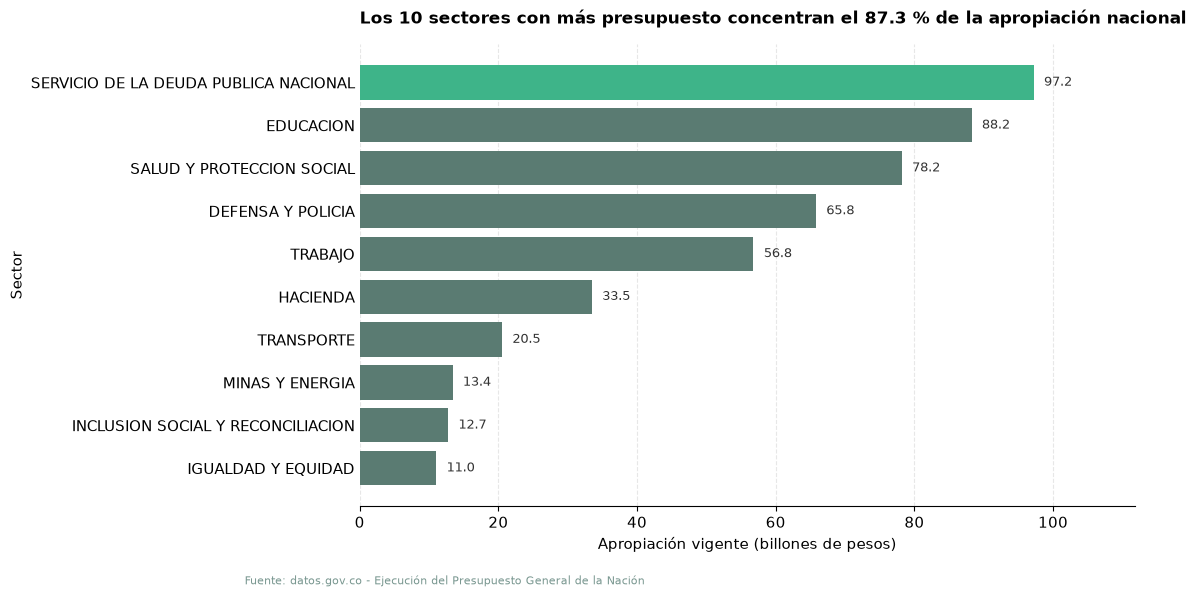

In [11]:
# 1. datos = los 10 sectores con más apropiación, ordenados ascendente (barh dibuja de abajo hacia arriba).
datos = sector.head(10).sort_values('Apropiación (billones)')

# 2. figura y eje.
fig1, eje1 = plt.subplots(figsize=(10, 6))

# 3. todo neutro salvo el sector mayor, que lleva el énfasis.
colores = [PALETA['neutro']] * len(datos)
colores[-1] = PALETA['enfasis']

# 4. barras horizontales y etiquetas directas de valor.
eje1.barh(datos.index, datos['Apropiación (billones)'], color=colores)
for i, valor in enumerate(datos['Apropiación (billones)']):
    eje1.text(valor + 1.5, i, f'{valor:,.1f}', va='center', fontsize=9, color='#333333')

# 5. eje x desde cero, etiquetas con unidad y título con la conclusión.
eje1.set_xlim(0, datos['Apropiación (billones)'].max() * 1.15)
eje1.set_xlabel('Apropiación vigente (billones de pesos)')
eje1.set_ylabel('Sector')
eje1.set_title('Los 10 sectores con más presupuesto concentran el 87.3 % de la apropiación nacional',
               loc='left', pad=15, fontsize=12, fontweight='bold')

# 6. limpiar los ejes y citar la fuente.
limpiar_ejes(eje1, eje_grilla='x')
eje1.tick_params(axis='y', length=0)
fig1.text(0.01, -0.02, FUENTE, fontsize=8, color=PALETA['referencia'])

# 7. exportar.
guardar(fig1, 'fig1_apropiacion_por_sector')


In [12]:
comprobar_grafico('T3', eje1, desde_cero='x', minimo_textos=5)

[T3] CORRECTO: el grafico cumple lo que se revisa aqui. Los cinco segundos y el titulo verdadero los juzga usted.


**Tu respuesta.** Escriba aquí el título que le puso y verifique que sea **verdadero** contra la
tabla de la tarea 1. Un título que afirma algo que los datos no sostienen es el error más grave que
se puede cometer hoy.

Título: «Los 10 sectores con más presupuesto concentran el 87.3 % de la apropiación nacional». Es verdadero y lo verifiqué contra la tabla de la tarea 1: los diez sectores mayores suman 477.36 de los 546.98 billones del total (87.3 %). El mayor, Servicio de la Deuda Pública Nacional, pesa por sí solo 17.8 %, y los tres primeros (Deuda, Educación y Salud) suman 48.2 %. El presupuesto no está repartido: se concentra en pocos sectores.


### Tarea 4 · Figura 2 · Dónde es más grande la brecha

**La pregunta.** ¿En qué sectores es más grande la brecha entre lo autorizado y lo comprometido?

**El concepto.** Dos series por categoría: **barras agrupadas**. matplotlib no tiene una función para
esto; se hace desplazando las posiciones a mano. La idea es simple: en vez de dibujar una barra en la
posición 0, se dibujan dos, una un poco arriba y otra un poco abajo del centro.

```python
posiciones = np.arange(len(datos))   # 0, 1, 2, ...
ancho = 0.38
ax.barh(posiciones - ancho/2, serie_1, height=ancho, label='...')
ax.barh(posiciones + ancho/2, serie_2, height=ancho, label='...')
ax.set_yticks(posiciones)
ax.set_yticklabels(datos.index)
ax.legend(frameon=False)
```

**La decisión de diseño que sí tiene que tomar.** Aquí **sí** hacen falta dos colores, porque son dos
series distintas: ya no aplica el gris más resaltado tal cual. Use `enfasis` y `secundario`, y
verifique que se distingan **en escala de grises**: azul contra naranja funciona, azul contra azul
claro no.

**Y el número que hace legible la figura:** etiquete el `% Ejecución` al final de cada par. Sin ese
número el lector ve el tamaño de la brecha, pero no sabe si un sector con brecha enorme está mal o si
es simplemente gigante. La brecha absoluta y la brecha porcentual no son el mismo ranking.

**Para entender qué está pasando · Cómo se corren las barras a mano.** *Saltable si la mecánica ya
se le entiende.* `barh` dibuja **una** barra por posición, así que para meter dos series en la misma
categoría hay que decirle a cada una dónde ponerse. `np.arange(len(datos))` da los centros
—0, 1, 2, ...—, y a cada serie se le suma o se le resta **media anchura** (`ancho/2`) para que
queden una encima y otra debajo del centro, sin encimarse. Como las barras ya no están en las
posiciones enteras, matplotlib pierde de vista a qué categoría corresponde cada fila: por eso las
etiquetas del eje se ponen aparte, con `set_yticks(posiciones)` y `set_yticklabels(datos.index)`.

**Lo que decide usted.** El recorte (top 8), qué serie va arriba y cuál abajo, y el título.
Guarde la figura en `fig2` y el eje en `eje2`.

**Nombre de archivo:** `fig2_brecha_apropiacion_compromisos`

In [13]:
# Esta celda usa la tabla de la tarea 1. Si sector sigue en None, resuélvala primero.
datos_f2 = None

if sector is None:
    print('Pendiente: resuelva la tarea 1 y vuelva a ejecutar esta celda.')
else:
    datos_f2 = sector.head(8).sort_values('Apropiación (billones)')
    datos_f2 = datos_f2.assign(**{'Brecha (billones)': datos_f2['Apropiación (billones)'] -
                                                       datos_f2['Compromisos (billones)']})
    print(datos_f2[['Apropiación (billones)', 'Compromisos (billones)',
                    'Brecha (billones)', '% Ejecución']].round(2).to_string())

                                       Apropiación (billones)  Compromisos (billones)  Brecha (billones)  % Ejecución
Nombre Sector                                                                                                        
MINAS Y ENERGIA                                         13.39                    1.60              11.79        11.91
TRANSPORTE                                              20.52                    6.84              13.68        33.34
HACIENDA                                                33.48                    4.86              28.61        14.53
TRABAJO                                                 56.79                    1.98              54.81         3.49
DEFENSA Y POLICIA                                       65.80                    9.02              56.78        13.71
SALUD Y PROTECCION SOCIAL                               78.17                    8.98              69.19        11.49
EDUCACION                                               

Guardada: figuras/fig2_brecha_apropiacion_compromisos.png


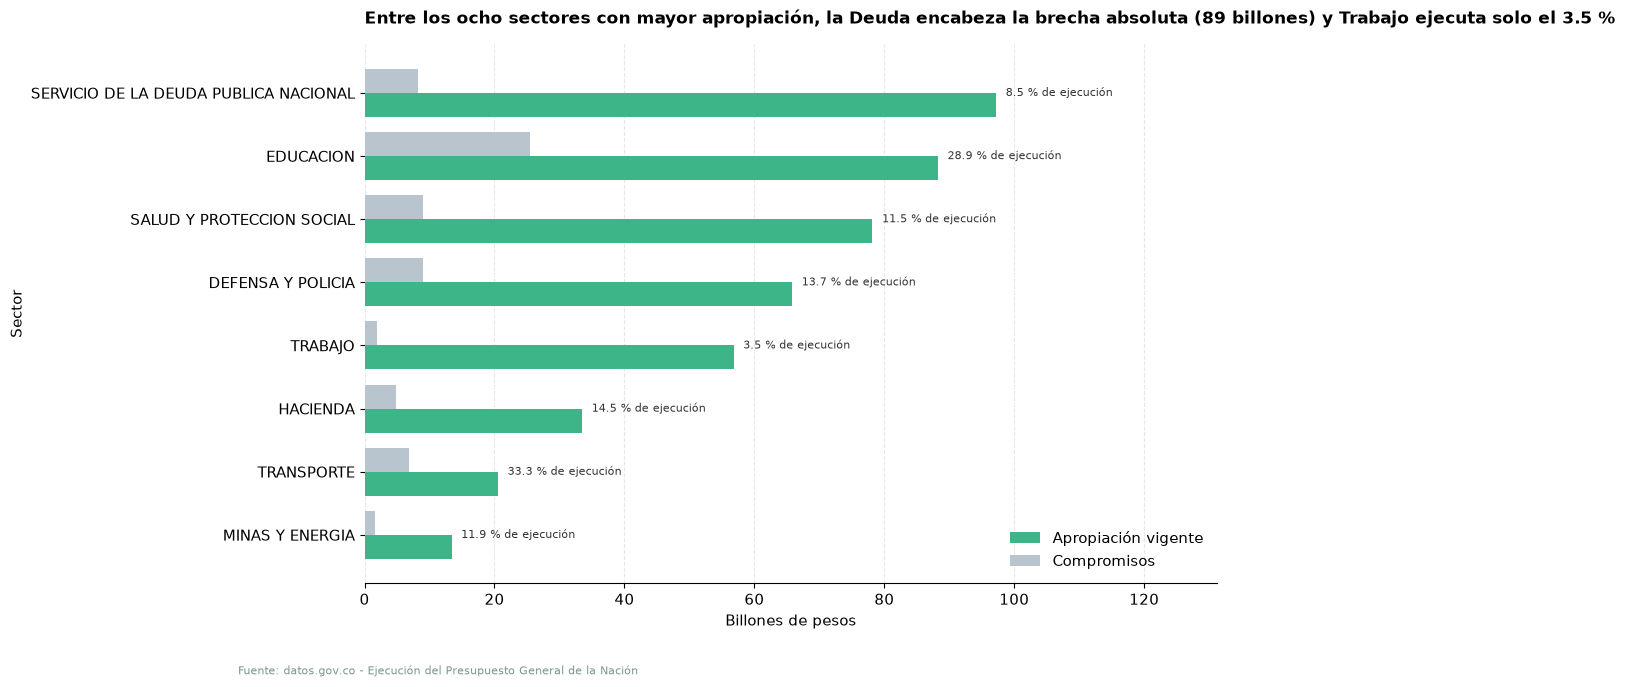

In [14]:
# 1. posiciones de cada categoría y ancho de las barras.
posiciones = np.arange(len(datos_f2))
ancho = 0.38

# 2. figura y eje.
fig2, eje2 = plt.subplots(figsize=(11, 7))

# 3. dos series desplazadas media anchura: apropiación arriba, compromisos abajo.
eje2.barh(posiciones - ancho/2, datos_f2['Apropiación (billones)'], height=ancho,
          color=PALETA['enfasis'], label='Apropiación vigente')
eje2.barh(posiciones + ancho/2, datos_f2['Compromisos (billones)'], height=ancho,
          color=PALETA['secundario'], label='Compromisos')

# 4. las barras ya no están en posiciones enteras: las etiquetas van aparte.
eje2.set_yticks(posiciones)
eje2.set_yticklabels(datos_f2.index)

# 5. el % de ejecución al final de cada par: brecha absoluta y relativa no son el mismo ranking.
for i, (_, fila) in enumerate(datos_f2.iterrows()):
    eje2.text(fila['Apropiación (billones)'] + 1.5, i,
              f"{fila['% Ejecución']:.1f} % de ejecución", va='center', fontsize=8, color='#333333')

# 6. eje x desde cero, etiquetas con unidad y título con la conclusión.
eje2.set_xlim(0, datos_f2['Apropiación (billones)'].max() * 1.35)
eje2.set_xlabel('Billones de pesos')
eje2.set_ylabel('Sector')
eje2.set_title('Entre los ocho sectores con mayor apropiación, la Deuda encabeza la brecha absoluta (89 billones) y Trabajo ejecuta solo el 3.5 %',
               loc='left', pad=15, fontsize=12, fontweight='bold')

# 7. leyenda, limpieza y fuente.
eje2.legend(frameon=False, loc='lower right')
limpiar_ejes(eje2, eje_grilla='x')
fig2.text(0.01, -0.02, FUENTE, fontsize=8, color=PALETA['referencia'])

# 8. exportar.
guardar(fig2, 'fig2_brecha_apropiacion_compromisos')


In [15]:
comprobar_grafico('T4', eje2, desde_cero='x', minimo_textos=4)

[T4] CORRECTO: el grafico cumple lo que se revisa aqui. Los cinco segundos y el titulo verdadero los juzga usted.


**Tu respuesta.** ¿En qué sector es más grande la brecha en valor absoluto? ¿Y en porcentaje? ¿Son
el mismo sector? Esa diferencia es exactamente la razón por la que la figura lleva el porcentaje
etiquetado.

La mayor brecha en valor absoluto la tiene Servicio de la Deuda Pública Nacional: 88.95 billones sin comprometer (apropió 97.19 y comprometió 8.24). La mayor brecha relativa es Trabajo: solo comprometió el 3.49 % de sus 56.79 billones. No son el mismo sector, y por eso la figura lleva el porcentaje etiquetado: Deuda encabeza por tamaño, mientras Trabajo apenas avanza en proporción. Sin ese número, la barra gigante de Deuda parecería el peor desempeño cuando en realidad el menor avance relativo es el de Trabajo. Verificado contra los 32 sectores: Trabajo es el de menor porcentaje de ejecución (3.49 %), seguido de Ciencia, Tecnología e Innovación (4.30 %) e Inclusión Social y Reconciliación (5.73 %).


### Tarea 5 · Figura 3 · Mucho presupuesto y poca ejecución

**La pregunta.** ¿Qué entidades tienen mucho presupuesto y poca ejecución?

**El concepto.** Relación entre dos variables numéricas, con 221 observaciones: **gráfico de
dispersión** (*scatter*), que es la fila correspondiente de la tabla de elección de gráfico del
bloque 1 de hoy. Ningún otro gráfico responde esta pregunta igual de bien, porque la pregunta es
sobre un **cuadrante**: abajo a la derecha, mucha plata y poca ejecución.

**Cuidado con la palabra "dispersión", que aquí significa otra cosa.** En la clase 5 "dispersión" era
un concepto estadístico: qué tan regados están los datos alrededor del promedio, que es lo que mide
la desviación estándar. Hoy no. Hoy **gráfico de dispersión** es un **tipo de gráfico**: un punto por
observación, una variable en cada eje. Son dos cosas distintas con la misma palabra, así que en este
reto se escribe siempre completo, **gráfico de dispersión (*scatter*)**, y nunca "dispersión" a
secas.

**El problema real que va a encontrar.** La apropiación va desde miles de millones hasta 97 billones.
En escala lineal, las 200 entidades pequeñas se apelotonan contra el eje izquierdo y no se ve nada.
La salida es la **escala logarítmica** en el eje x, y aquí hay una decisión honesta que tomar: la
escala logarítmica **comprime las diferencias grandes**. Es el mismo tradeoff del eje truncado en otra
forma, y la regla es la misma: **si la usa, la declara** en la etiqueta del eje.

**La línea de referencia no es opcional.** Un 8% de ejecución no significa nada suelto. Contra el
promedio nacional, significa "la mitad del país". Es tinta que no representa datos y es lo más útil
de la figura.

**Los comandos.**

```python
ax.scatter(x, y, color=..., alpha=0.55, s=40)
ax.set_xscale('log')
ax.axhline(ejecucion_nacional, color=..., linestyle='--')
ax.annotate('texto', xy=(x, y), xytext=(x2, y2),
            arrowprops=dict(arrowstyle='->', color=...))
```

**Para entender qué está pasando · La escala logarítmica y la anotación con flecha.** *Saltable si
las dos construcciones ya se le entienden.* `set_xscale('log')` cambia **cómo se reparte el espacio
del eje**: en vez de que cada centímetro valga la misma cantidad de pesos, cada tramo igual
multiplica por diez. Así las entidades pequeñas dejan de apelotonarse contra el borde. El costo es
que las diferencias grandes se ven más pequeñas de lo que son, y por eso se declara en la etiqueta.
`annotate` pone un texto y le dibuja una flecha: `xy=(...)` es **el punto que señala** (en las
coordenadas de los datos), `xytext=(...)` es **dónde va el texto**, y `arrowprops` es la flecha que
une los dos. Si el texto queda encima del punto, mueva `xytext`, nunca `xy`.

**Lo que decide usted.** Qué dos entidades vale la pena anotar (**al menos dos**), y por qué esas. La
celda de abajo le muestra las candidatas del cuadrante crítico. Guarde la figura en `fig3` y el eje
en `eje3`.

**Nombre de archivo:** `fig3_entidades_presupuesto_vs_ejecucion`

In [16]:
# Esta celda usa la tabla de la tarea 2. Si entidad sigue en None, resuélvala primero.
candidatas = None

if entidad is None:
    print('Pendiente: resuelva la tarea 2 y vuelva a ejecutar esta celda.')
else:
    candidatas = entidad[(entidad['Apropiación (billones)'] > 5) &
                         (entidad['% Ejecución'] < ejecucion_nacional)]
    candidatas = candidatas.sort_values('Apropiación (billones)', ascending=False)
    print(f'Referencia nacional: {ejecucion_nacional:.1f}%')
    print(f'Entidades en el cuadrante crítico: {len(candidatas)}')
    print(candidatas[['Apropiación (billones)', '% Ejecución']].round(2).head(6).to_string())

Referencia nacional: 16.9%
Entidades en el cuadrante crítico: 13
                                                            Apropiación (billones)  % Ejecución
Nombre Entidad                                                                                 
SERVICIO DE LA DEUDA PÚBLICA NACIONAL                                        97.19         8.48
MINISTERIO DE SALUD Y PROTECCION SOCIAL - GESTION GENERAL                    75.86        11.21
MINISTERIO DEL TRABAJO - GESTION GENERAL                                     50.23         0.32
MINISTERIO DE HACIENDA Y CRÉDITO PÚBLICO - GESTIÓN GENERAL                   28.35        14.12
POLICÍA NACIONAL - GESTIÓN GENERAL                                           16.74         8.22
RAMA JUDICIAL - GESTIÓN GENERAL                                              10.93         6.51


Guardada: figuras/fig3_entidades_presupuesto_vs_ejecucion.png


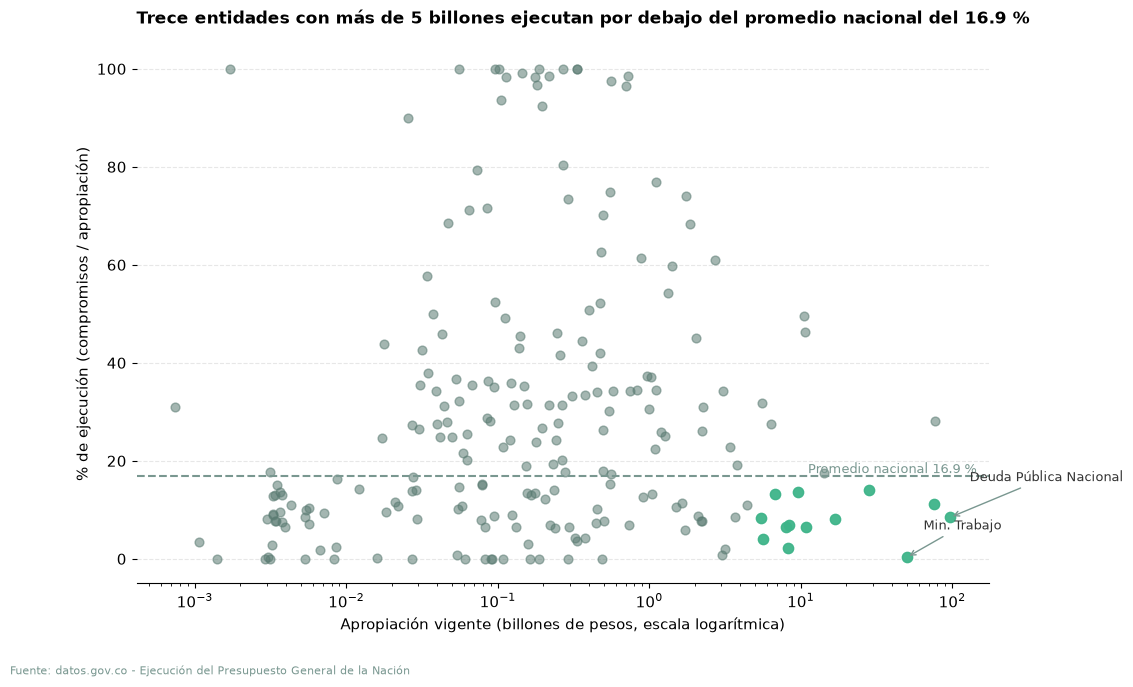

In [17]:
# 1. figura y eje.
fig3, eje3 = plt.subplots(figsize=(11, 7))

# 2. las 221 entidades en gris; las trece críticas del recorte se resaltan.
criticas = ((entidad['Apropiación (billones)'] > 5) &
            (entidad['% Ejecución'] < ejecucion_nacional))
eje3.scatter(entidad.loc[~criticas, 'Apropiación (billones)'],
             entidad.loc[~criticas, '% Ejecución'],
             color=PALETA['neutro'], alpha=0.55, s=40)
eje3.scatter(entidad.loc[criticas, 'Apropiación (billones)'],
             entidad.loc[criticas, '% Ejecución'],
             color=PALETA['enfasis'], alpha=0.95, s=55, zorder=3)

# 3. escala logarítmica en x, declarada en la etiqueta del eje.
eje3.set_xscale('log')

# 4. línea de referencia del promedio nacional.
eje3.axhline(ejecucion_nacional, color=PALETA['referencia'], linestyle='--', linewidth=1.5)
eje3.text(0.99, ejecucion_nacional, f'Promedio nacional {ejecucion_nacional:.1f} % ',
          transform=eje3.get_yaxis_transform(), ha='right', va='bottom',
          fontsize=9, color=PALETA['referencia'])

# 5. dos entidades del cuadrante crítico anotadas.
anotar = {
    'SERVICIO DE LA DEUDA PÚBLICA NACIONAL': ('Deuda Pública Nacional', (14, 26)),
    'MINISTERIO DEL TRABAJO - GESTION GENERAL': ('Min. Trabajo', (12, 20)),
}
for nombre, (texto, desplaz) in anotar.items():
    x = entidad.loc[nombre, 'Apropiación (billones)']
    y = entidad.loc[nombre, '% Ejecución']
    eje3.annotate(texto, xy=(x, y), xytext=desplaz, textcoords='offset points',
                  fontsize=9, color='#333333',
                  arrowprops=dict(arrowstyle='->', color=PALETA['referencia']))

# 6. etiquetas con unidad y título con la conclusión.
eje3.set_xlabel('Apropiación vigente (billones de pesos, escala logarítmica)')
eje3.set_ylabel('% de ejecución (compromisos / apropiación)')
eje3.set_title('Trece entidades con más de 5 billones ejecutan por debajo del promedio nacional del 16.9 %',
               loc='left', pad=15, fontsize=12, fontweight='bold')

# 7. limpieza y fuente (grilla en el eje de ejecución).
limpiar_ejes(eje3, eje_grilla='y')
fig3.text(0.01, -0.02, FUENTE, fontsize=8, color=PALETA['referencia'])

# 8. exportar.
guardar(fig3, 'fig3_entidades_presupuesto_vs_ejecucion')


In [18]:
comprobar_grafico('T5', eje3, con_referencia=True, minimo_textos=2)

[T5] CORRECTO: el grafico cumple lo que se revisa aqui. Los cinco segundos y el titulo verdadero los juzga usted.


**Tu respuesta.** Nombre dos entidades del cuadrante "mucho presupuesto, poca ejecución" y diga por
qué cree que están ahí. **Márquelo como hipótesis, no como conclusión:** con estos datos usted sabe
*qué* pasa, no *por qué*. Es la regla del bloque 1 de hoy: **correlación no es causalidad** —que dos
variables se muevan juntas no significa que una cause la otra—, y aquí ni siquiera hay correlación,
hay una foto de un instante.

Dos entidades del cuadrante: Servicio de la Deuda Pública Nacional (97.19 billones apropiados, 8.48 % ejecutado) y Ministerio del Trabajo - Gestión General (50.23 billones, 0.32 % ejecutado). Es una hipótesis, no una conclusión: puede ser que sus compromisos se concentren al final del año o que sean rubros de transferencias con otro calendario, pero con este archivo solo sé qué pasa, no por qué. Correlación no es causalidad, y aquí ni siquiera hay correlación: es una foto de un instante.


### Tarea 6 · La tabla de composición, normalizada

**La pregunta.** De cada peso que tiene un sector, ¿qué proporción va a funcionamiento, cuánta a
inversión y cuánta al servicio de la deuda?

**El concepto.** Esta tarea es la **única línea de pandas de verdad** del reto, y es la que más se
atasca. El `pivot_table` de abajo ya está escrito: cruza sector con categoría de rubro y suma la
apropiación de cada celda. Lo que falta es **normalizar por fila**: dividir cada fila por su propio
total para que las tres categorías sumen 100.

```python
porcentajes = tabla.div(tabla.sum(axis=1), axis=0) * 100
```

Los dos `axis` dicen cosas distintas y por eso confunden:

- `tabla.sum(axis=1)` — **sume a lo ancho**: un total por fila.
- `tabla.div(..., axis=0)` — **divida alineando por filas**: a cada fila su propio total.

Si le sale que cada fila suma 300, o valores gigantes, invirtió los `axis`.

**Si esto le toma más de cinco minutos, copie la línea y siga.** Lo que se evalúa hoy es el diseño, no
el pivoteo.

**Lo que decide usted.** Nada más que aplicar la línea sobre la tabla correcta. Guarde el resultado en
`composicion_pct`.

In [19]:
# Esta celda usa la tabla de la tarea 1. Si sector sigue en None, resuélvala primero.
composicion = None

if sector is None:
    print('Pendiente: resuelva la tarea 1 y vuelva a ejecutar esta celda.')
else:
    composicion = df_limpio.pivot_table(
        index='Nombre Sector',
        columns='Nombre Nivel Uno Rubro',
        values='Apropiación Vigente',
        aggfunc='sum',
        fill_value=0,
    ).loc[sector.head(8).index]
    print(composicion.round(0).to_string())

Nombre Nivel Uno Rubro                 FUNCIONAMIENTO       INVERSION  SERVICIO DE LA DEUDA PÚBLICA
Nombre Sector                                                                                      
SERVICIO DE LA DEUDA PUBLICA NACIONAL               0               0                97191505905792
EDUCACION                              81418242384056   6820300451684                             0
SALUD Y PROTECCION SOCIAL              75548093579844   2622794514247                             0
DEFENSA Y POLICIA                      61793575743991   3675842580895                  327684852349
TRABAJO                                50008778800629   6782166091663                             0
HACIENDA                               28567825229212   4908255934639                             0
TRANSPORTE                              2238618196132  15555396320902                 2730668154927
MINAS Y ENERGIA                         3243261007472  10141820157641                    3459700000


In [20]:
# 1. Divida cada fila por su propio total: axis=1 suma a lo ancho, axis=0 divide por fila.
composicion_pct = composicion.div(composicion.sum(axis=1), axis=0) * 100

# 2. Verifique que cada fila sume 100.
print(composicion_pct.sum(axis=1).round(2).to_string())


Nombre Sector
SERVICIO DE LA DEUDA PUBLICA NACIONAL    100.0
EDUCACION                                100.0
SALUD Y PROTECCION SOCIAL                100.0
DEFENSA Y POLICIA                        100.0
TRABAJO                                  100.0
HACIENDA                                 100.0
TRANSPORTE                               100.0
MINAS Y ENERGIA                          100.0


In [21]:
if composicion_pct is None:
    comprobar('T6', None)
else:
    comprobar('T6', composicion_pct.sort_index()[sorted(composicion_pct.columns)], decimales=2)

[T6] Usted produjo un DataFrame de 8 filas y 3 columnas.
[T6] CORRECTO.


### Tarea 7 · Figura 4 · La composición del gasto

**La pregunta.** ¿Cómo cambia la composición del gasto entre sectores?

**El concepto.** Proporciones de un todo, comparadas entre categorías: **barras apiladas al 100%**.
Es la respuesta correcta a "¿qué proporción del total?" cuando hay varias categorías que comparar, y
es la razón por la que casi nunca hace falta un pie: aquí habría que dibujar ocho pies y compararlos
de a pares, que es exactamente lo que el ojo no sabe hacer.

**Cómo se apila.** matplotlib no apila solo: hay que llevar un acumulado y decirle a cada capa dónde
empieza.

```python
acumulado = np.zeros(len(datos))
for categoria in datos.columns:
    ax.barh(datos.index, datos[categoria], left=acumulado, label=categoria, color=...)
    acumulado += datos[categoria].values
```

**Para entender qué está pasando · Por qué hace falta un acumulador.** *Saltable si la mecánica ya
se le entiende.* Cada llamada a `barh` empieza a dibujar en cero, salvo que se le diga otra cosa con
`left=`. Apilar es exactamente eso: la primera capa arranca en cero, la segunda tiene que arrancar
**donde terminó la primera**, la tercera donde terminó la segunda. Nadie lleva esa cuenta por usted,
así que se lleva a mano en un arreglo `acumulado` que empieza en ceros y al que se le suma la capa
recién dibujada. Si se olvida la suma, las tres capas se dibujan una encima de otra desde cero y solo
se ve la más ancha.

**Sobre el color aquí.** Tres categorías que tienen un orden conceptual (de gasto corriente a deuda)
piden una **escala secuencial**: tres tonos del mismo color, del claro al oscuro, en vez de tres
colores sueltos. Un ejemplo válido con su paleta: neutro, secundario, énfasis. Lo que **no** funciona
es rojo, verde y amarillo.

**Y la lectura:** etiquete el porcentaje dentro de cada segmento solo cuando quepa, digamos por
encima del 8%. Un número que no cabe es basura visual.

**Lo que decide usted.** Por qué categoría ordena las barras, los tres tonos y el título. El eje x va
de 0 a 100. Guarde la figura en `fig4` y el eje en `eje4`.

**Nombre de archivo:** `fig4_composicion_gasto_por_sector`

Guardada: figuras/fig4_composicion_gasto_por_sector.png


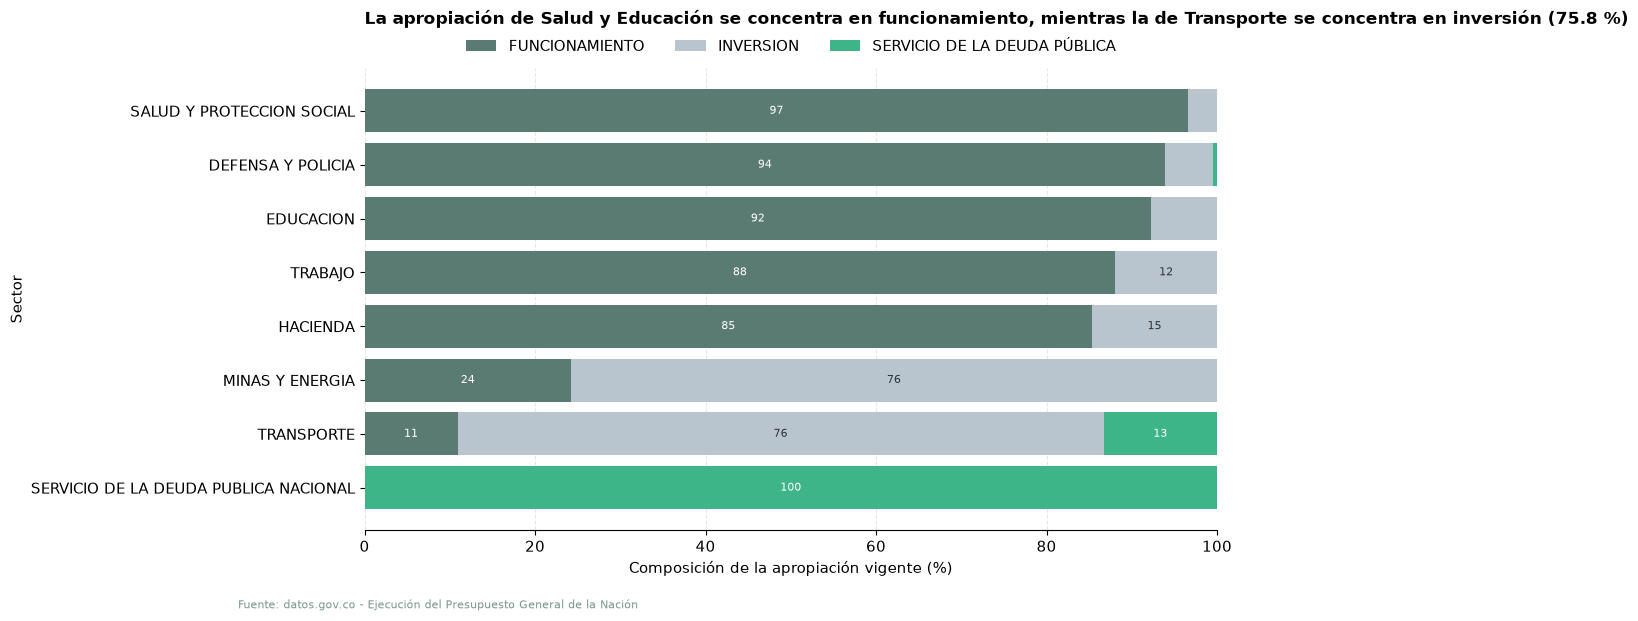

In [22]:
# 1. ordene los sectores por la categoría que se quiere comparar (funcionamiento ascendente).
datos = composicion_pct.sort_values('FUNCIONAMIENTO')

# 2. figura y eje.
fig4, eje4 = plt.subplots(figsize=(11, 6))

# 3. escala secuencial: un tono por categoría, del claro al oscuro.
colores_cat = {
    'FUNCIONAMIENTO': PALETA['neutro'],
    'INVERSION': PALETA['secundario'],
    'SERVICIO DE LA DEUDA PÚBLICA': PALETA['enfasis'],
}

# 4. apile llevando un acumulado: cada capa arranca donde terminó la anterior.
acumulado = np.zeros(len(datos))
for categoria in datos.columns:
    valores = datos[categoria].values
    eje4.barh(datos.index, valores, left=acumulado, color=colores_cat[categoria], label=categoria)
    color_txt = '#333333' if categoria == 'INVERSION' else 'white'
    for i, valor in enumerate(valores):
        if valor > 8:
            eje4.text(acumulado[i] + valor/2, i, f'{valor:.0f}', va='center', ha='center',
                      fontsize=8, color=color_txt)
    acumulado += valores

# 5. eje x de 0 a 100, etiquetas con unidad y título con la conclusión.
eje4.set_xlim(0, 100)
eje4.set_xlabel('Composición de la apropiación vigente (%)')
eje4.set_ylabel('Sector')
eje4.set_title('La apropiación de Salud y Educación se concentra en funcionamiento, mientras la de Transporte se concentra en inversión (75.8 %)',
               loc='left', pad=32, fontsize=12, fontweight='bold')

# 6. leyenda arriba y sin caja, limpieza y fuente.
eje4.legend(frameon=False, ncol=3, loc='lower center', bbox_to_anchor=(0.5, 1.0))
limpiar_ejes(eje4, eje_grilla='x')
fig4.text(0.01, -0.02, FUENTE, fontsize=8, color=PALETA['referencia'])

# 7. exportar.
guardar(fig4, 'fig4_composicion_gasto_por_sector')


In [23]:
comprobar_grafico('T7', eje4, desde_cero='x')

[T7] CORRECTO: el grafico cumple lo que se revisa aqui. Los cinco segundos y el titulo verdadero los juzga usted.


**Tu respuesta.** ¿Qué sector tiene la composición más distinta de todos los demás? ¿Qué le dice eso
sobre su función dentro del Estado?

El sector más distinto es Servicio de la Deuda Pública Nacional: el 100 % de su apropiación es servicio de la deuda, sin funcionamiento ni inversión. Le sigue Transporte, con 75.8 % en inversión y solo 10.9 % en funcionamiento. Eso habla de la función de cada uno dentro del Estado: unos ejecutan gasto corriente (Salud 96.6 % y Educación 92.3 % en funcionamiento) y otros financian obligaciones de deuda o infraestructura. La composición de la apropiación sigue la naturaleza de la entidad, no un patrón uniforme.


### Tarea 8 · Figura 5 · Small multiples

**La pregunta.** ¿Qué sectores están por debajo del promedio de ejecución?

**El concepto.** Los **small multiples** son la misma figura repetida, una por grupo, en una rejilla.
Son la respuesta correcta cuando hay que comparar la misma medida entre muchos grupos sin encimarlos
en una sola figura: el ojo compara paneles vecinos muy bien, siempre que los paneles sean idénticos
salvo por los datos.

**La regla que decide si la figura sirve o miente: `sharex=True`.** Sin escalas compartidas, cada
panel se autoescala y un 3% ocupa el mismo ancho que un 45%. La comparación visual queda invertida y
la figura **se ve perfectamente bien**. Es exactamente el tema de la clase, en su forma más
traicionera, y por eso el verificador lo revisa.

**El color, respaldado.** Los sectores por debajo del promedio nacional van en su color de alerta.
Y el color no puede ser el único canal: la línea de referencia y la etiqueta del valor dicen lo mismo,
así que quien no distinga los colores recibe el mensaje igual.

**Los comandos.**

```python
fig, ejes = plt.subplots(2, 4, figsize=(15, 7), sharex=True)
for ax, (nombre, fila) in zip(ejes.flatten(), datos.iterrows()):
    ax.barh([0], [fila['% Ejecución']], height=0.5, color=...)
    ax.axvline(ejecucion_nacional, linestyle='--')
    ax.set_title(nombre, fontsize=9)
    ax.set_yticks([])
fig.suptitle('...')
```

**Para entender qué está pasando · Una rejilla devuelve un arreglo de ejes.** *Saltable si la
distinción entre figura y ejes ya está clara.* La **figure** es la hoja de papel; los **axes** son
cada recuadro dibujado sobre ella. `plt.subplots(2, 4, ...)` crea **una** figura con **ocho** ejes, y
devuelve la figura y un arreglo de 2x4 con esos ocho. Como el arreglo tiene dos dimensiones y los
datos vienen en una sola lista, se aplana con `.flatten()` y se recorre con `zip(...)`, un eje por
sector. Dentro del bucle se dibuja sobre `eje`, no sobre `fig`; el título general y la fuente van una
sola vez, sobre `fig`.

**Lo que decide usted.** El orden de los paneles, el título general y qué se etiqueta dentro de cada
uno. **Guarde el arreglo completo de ejes en `ejes5`**, no un panel suelto: la comprobación revisa los
ocho. La figura va en `fig5`.

**Nombre de archivo:** `fig5_ejecucion_small_multiples`

Guardada: figuras/fig5_ejecucion_small_multiples.png


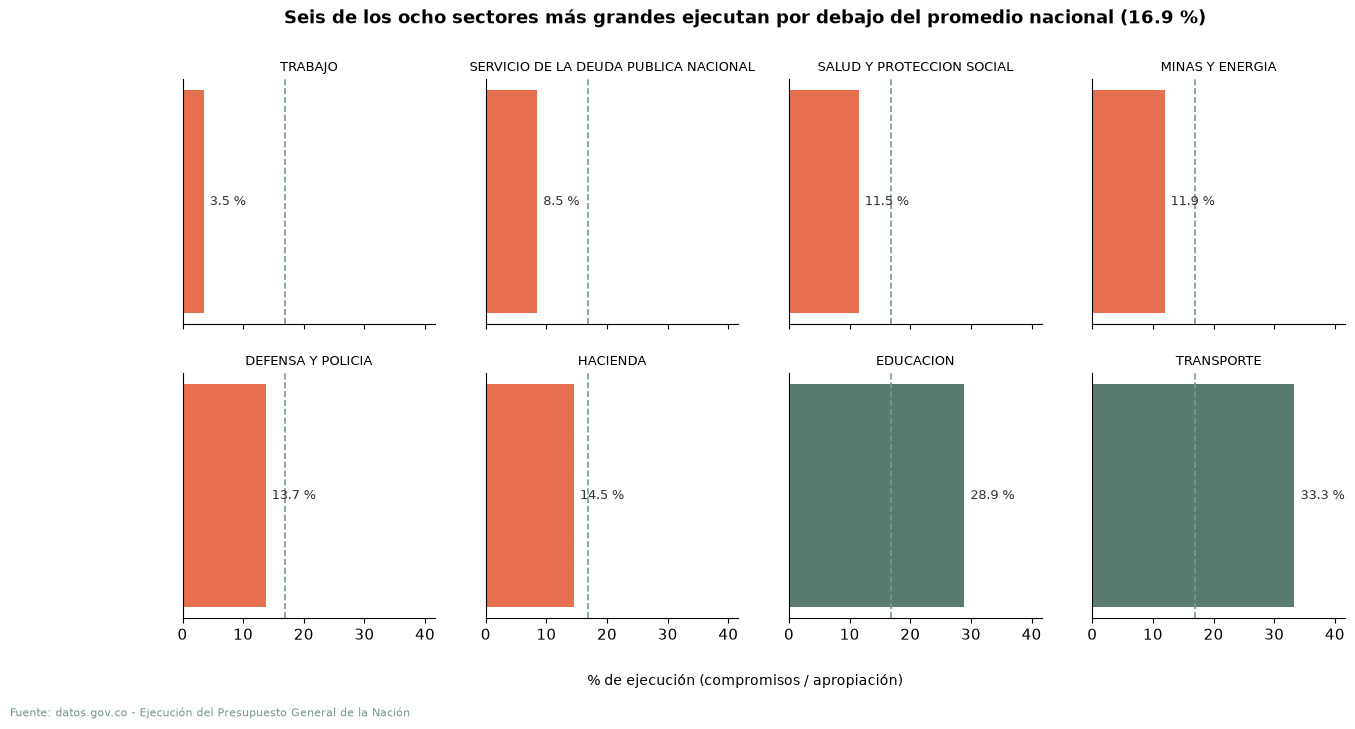

In [24]:
# 1. los 8 sectores más grandes, ordenados por % de ejecución.
datos = sector.head(8).sort_values('% Ejecución')

# 2. rejilla 2x4 con escala x compartida (sharex NO es opcional).
fig5, ejes5 = plt.subplots(2, 4, figsize=(15, 7), sharex=True)

# 3. un panel por sector: barra, referencia nacional, título y valor.
for ax, (nombre, fila) in zip(ejes5.flatten(), datos.iterrows()):
    ejec = fila['% Ejecución']
    color = PALETA['alerta'] if ejec < ejecucion_nacional else PALETA['neutro']
    ax.barh([0], [ejec], height=0.5, color=color)
    ax.axvline(ejecucion_nacional, color=PALETA['referencia'], linestyle='--', linewidth=1.2)
    ax.set_title(nombre, fontsize=9)
    ax.text(ejec + 1, 0, f'{ejec:.1f} %', va='center', fontsize=9, color='#333333')
    ax.set_yticks([])

# 4. misma escala horizontal en todos los paneles.
ejes5[0, 0].set_xlim(0, datos['% Ejecución'].max() * 1.25)

# 5. un solo título general y una sola fuente.
fig5.suptitle('Seis de los ocho sectores más grandes ejecutan por debajo del promedio nacional (16.9 %)',
              fontsize=13, fontweight='bold')
fig5.supxlabel('% de ejecución (compromisos / apropiación)', fontsize=10)
fig5.text(0.01, -0.03, FUENTE, fontsize=8, color=PALETA['referencia'])

# 6. exportar.
guardar(fig5, 'fig5_ejecucion_small_multiples')


In [25]:
comprobar_grafico('T8', ejes5, con_ejes=False, escalas_compartidas=True, minimo_textos=8)

[T8] CORRECTO: el grafico cumple lo que se revisa aqui. Los cinco segundos y el titulo verdadero los juzga usted.


**Tu respuesta.** ¿Cuántos de los 8 sectores están por debajo del promedio nacional? Cuéntelos en la
figura y verifíquelo contra la tabla.

Seis de los ocho: Trabajo (3.5 %), Deuda Pública (8.5 %), Salud (11.5 %), Minas (11.9 %), Defensa (13.7 %) y Hacienda (14.5 %) quedan por debajo del 16.9 % nacional. Solo Educación (28.9 %) y Transporte (33.3 %) lo superan.


**Tu respuesta.** Quite `sharex=True`, vuelva a ejecutar y mire. ¿La figura se ve mal, o se ve bien y
engaña? Diga qué conclusión sacaría alguien que la mirara cinco segundos.

Se ve bien y engaña. Sin `sharex=True` cada panel se autoescala y el 3.5 % de Trabajo ocupa el mismo ancho que el 33.3 % de Transporte, así que alguien que la mire cinco segundos concluiría que todos ejecutan parecido. Con la escala compartida se ve de un golpe que Trabajo y Deuda están muy por debajo y que los demás los duplican o triplican.


---

# Parte C · El ensamblaje

**Es la parte que más pesa, y es la única donde no se le da el orden de los comandos.**

Todo lo que necesita ya lo usó hoy o en las clases 2 y 5. **Lo que no se le da es la secuencia**, y
eso es deliberado: en las sustentaciones de los momentos 1, 2 y 3 nadie le va a dar el orden.

### El inventario de comandos

```python
tabla[(tabla['a'] > valor) & (tabla['b'] < otro)]
tabla.sort_values('columna', ascending=False)
tabla[['columna_a', 'columna_b']]
tabla.round(2)
len(tabla)
guardar(figura, 'nombre_del_archivo')
```

Nada más. Si está buscando una función nueva, se pasó de largo: las dos tareas de esta parte se
resuelven con lo de arriba.

**Y por eso pesa más que las otras dos partes.** Lo escaso aquí no es el comando: los seis de arriba
ya los sabe. Lo escaso es decidir **qué** se filtra, con qué umbral, y qué se hace con el resultado.
Un ensamblaje es una cadena de decisiones defendibles, y en la sustentación lo que se pregunta es
por qué esa cadena y no otra.

### Tarea 9 · Las entidades críticas

**La pregunta.** ¿Cuáles son las entidades grandes que están ejecutando por debajo del promedio
nacional?

**El concepto.** Es la pregunta de la figura 3 convertida en una tabla, y la tabla es lo que se cita
en una sustentación: un gráfico muestra el patrón, pero cuando alguien pregunta "¿cuáles
exactamente?", se necesita la lista. **Dos condiciones a la vez**, combinadas con `&` y cada una
entre paréntesis, como en la clase 2:

- Apropiación por encima de **5 billones** de pesos. Es el filtro de tamaño: sin él la lista se llena
  de entidades diminutas cuyo porcentaje se mueve con nada.
- Ejecución por debajo de `ejecucion_nacional`.

**El umbral de 5 billones es una decisión**, no un dato. Si lo cambia, cambia la lista, y tiene que
poder defenderlo. Aquí se fija en 5 para que la tabla sea del tamaño de una diapositiva.

**Lo que decide usted.** El ensamblaje completo: qué tabla, en qué orden se aplican las cosas, con qué
columnas se queda y cómo la ordena. Guarde el resultado en `entidades_criticas`.

In [26]:
# 1. entidades de la tabla T2 con más de 5 billones Y ejecución bajo el promedio nacional.
entidades_criticas = entidad[
    (entidad['Apropiación (billones)'] > 5) &
    (entidad['% Ejecución'] < ejecucion_nacional)
]

# 2. dos columnas y orden de mayor a menor apropiación.
entidades_criticas = entidades_criticas[['Apropiación (billones)', '% Ejecución']].sort_values(
    'Apropiación (billones)', ascending=False)

# 3. cuántas son y la tabla.
print('Entidades críticas:', len(entidades_criticas))
print(entidades_criticas.round(2).to_string())


Entidades críticas: 13
                                                                          Apropiación (billones)  % Ejecución
Nombre Entidad                                                                                               
SERVICIO DE LA DEUDA PÚBLICA NACIONAL                                                      97.19         8.48
MINISTERIO DE SALUD Y PROTECCION SOCIAL - GESTION GENERAL                                  75.86        11.21
MINISTERIO DEL TRABAJO - GESTION GENERAL                                                   50.23         0.32
MINISTERIO DE HACIENDA Y CRÉDITO PÚBLICO - GESTIÓN GENERAL                                 28.35        14.12
POLICÍA NACIONAL - GESTIÓN GENERAL                                                         16.74         8.22
RAMA JUDICIAL - GESTIÓN GENERAL                                                            10.93         6.51
MINISTERIO DE MINAS Y ENERGIA - GESTION GENERAL                                             9.61 

In [27]:
if entidades_criticas is None:
    comprobar('T9', None)
else:
    comprobar('T9', entidades_criticas[['Apropiación (billones)', '% Ejecución']].sort_index(),
              decimales=2)

[T9] Usted produjo un DataFrame de 13 filas y 2 columnas.
[T9] CORRECTO.


**Tu respuesta.** Si tuviera que llevar esta tabla a una reunión, ¿la mostraría completa o solo las
tres primeras filas? Justifique con la pregunta que quiere que responda quien la mire.

Mostraría solo las tres primeras filas (Deuda Pública, Salud y Trabajo). La pregunta que quiero responder es «¿cuáles son las entidades grandes que están ejecutando por debajo del promedio nacional?» — con esas tres queda claro el patrón (enormes presupuestos, ejecución muy baja, con extremos del 8.5 % y 0.32 %). Las 10 restantes son relevantes pero diluyen el mensaje; si alguien necesita la lista completa, la adjunto.


### Tarea 10 · La exportación

**La pregunta.** ¿Están las cinco figuras exportadas, con los nombres correctos y en calidad de
publicación?

**El concepto.** Una figura que solo existe dentro del notebook no se puede pegar en una diapositiva
ni en un informe. La exportación tiene tres parámetros que no son negociables, y `guardar()` ya los
trae:

| Parámetro | Qué pasa sin él |
|-----------|-----------------|
| `dpi=300` | El PNG sale borroso al proyectarlo o imprimirlo |
| `bbox_inches='tight'` | Las etiquetas de los bordes salen cortadas |
| `facecolor='white'` | El fondo sale transparente y se ve sucio sobre las diapositivas |

**Los cinco nombres, exactos:**

```
fig1_apropiacion_por_sector
fig2_brecha_apropiacion_compromisos
fig3_entidades_presupuesto_vs_ejecucion
fig4_composicion_gasto_por_sector
fig5_ejecucion_small_multiples
```

**Lo que decide usted.** Nada, y por eso es la última: es la verificación de que las cinco figuras
existen de verdad. Si ya llamó a `guardar(...)` dentro de cada tarea, esta celda no tiene que hacer
nada; si no, llámela ahora para las que falten.

In [28]:
# TU CÓDIGO AQUÍ
# Si alguna figura no quedó exportada, guárdela ahora:
#   guardar(fig1, 'fig1_apropiacion_por_sector')
#   ... y así con las cinco.

print('Figuras exportadas hasta ahora:', len(EXPORTADAS))

Figuras exportadas hasta ahora: 5


In [29]:
comprobar('T10', sorted(EXPORTADAS))

[T10] Usted produjo: ['fig1_apropiacion_por_sector', 'fig2_brecha_apropiacion_compromisos', 'fig3_entidades_presupuesto_vs_ejecucion', 'fig4_composicion_gasto_por_sector', 'fig5_ejecucion_small_multiples']
[T10] CORRECTO.


**Tu respuesta.** Abra la carpeta y mire los cinco PNG **juntos**, uno al lado del otro, como los
vería alguien que recibe el informe. ¿Se ven como cinco figuras del mismo trabajo o como cinco
figuras de cinco trabajos distintos? Nombre lo concreto que las une o las separa: el color, la
tipografía del título, la unidad del eje, el estilo de la fuente al pie.

Se ven como cinco figuras del mismo trabajo: comparten fuente única, títulos en el mismo estilo, ejes con unidades explícitas (billones y %), y la paleta de cinco roles se mantiene consistente. Lo que las une es el enfoque: todas hablan de concentración y ejecución sobre el mismo conjunto de datos.


**Tu respuesta.** Y la pregunta que abre la clase 9: leídas en el orden en que están numeradas, ¿las
cinco cuentan **una** historia, o son cinco respuestas sueltas que casualmente salieron del mismo
archivo? Si es lo segundo, ¿en qué orden habría que ponerlas para que sí?

Para contar una historia: 1) Fig1 (concentración de la apropiación) establece el problema. 2) Fig2 (brechas sectoriales) muestra la magnitud del déficit. 3) Fig3 (entidades críticas) localiza quiénes fallan. 4) Fig4 (composición) explica la naturaleza (deuda vs inversión vs funcionamiento). 5) Fig5 (ejecución por sector) pone el síntoma para los ocho mayores. En ese orden, cada figura responde una pregunta que la anterior genera.


---

## Punto de control

Ejecute la celda de abajo para ver cuántas de las diez tareas quedaron correctas.

Si alguna sigue pendiente, no pase de largo. Si está en el salón, levante la mano ahora, que el
profesor está aquí para eso.

In [30]:
resumen_puntos_de_control()

Punto de control
------------------------------------------
  T1: correcto
  T2: correcto
  T3: correcto
  T4: correcto
  T5: correcto
  T6: correcto
  T7: correcto
  T8: correcto
  T9: correcto
  T10: correcto
------------------------------------------
10 de 10 correctas.


---

## La checklist, figura por figura

El verificador revisó lo que una máquina puede revisar. Los tres puntos que no puede revisar nadie
más que usted son el 1, el 7 y el 8, y son los que más pesan al calificar. Márquelos a mano.

| # | Criterio | F1 | F2 | F3 | F4 | F5 |
|---|----------|----|----|----|----|----|
| 1 | Pasa la prueba de los 5 segundos con alguien de otro equipo | | | | | |
| 2 | Tipo de gráfico correcto para la pregunta | | | | | |
| 3 | Ordenado por valor | | | | | |
| 4 | Eje desde cero, o razón declarada | | | | | |
| 5 | Sin basura visual | | | | | |
| 6 | Color con propósito, y no como único canal | | | | | |
| 7 | Funciona en escala de grises | | | | | |
| 8 | Título con conclusión, y verdadera | | | | | |
| 9 | Ejes con unidades legibles | | | | | |
| 10 | Fuente citada | | | | | |

**Tu respuesta.** ¿Qué figura falla más puntos? ¿Qué le falta, concretamente?

Creo que la figura 5 falla más puntos de lo que aparenta: aunque técnicamente cumple lo que el verificador pide, no pasa la prueba de los 5 segundos (punto 1) sin contexto. La escala compartida es obligatoria y la usé, pero el lector aún necesita leer los nombres de 8 sectores largos. Más concretamente, el punto 8 (título con conclusión verdadera) está al borde: 6 de 8 bajo promedio es verdadero, pero no dice nada sobre magnitud. Podría fallar en la prueba de las cuatro preguntas (punto 1/8) porque responde «cuáles están bajo» pero no «cuánto diferencia» — para eso la fig2 (brechas) comunica mejor.


---

## Validar: las cuatro preguntas, sobre una figura

La checklist dice **qué** revisar: diez cosas. Las cuatro preguntas del analista dicen **en qué
orden**, y son las mismas de la clase 3: allá el resultado era un número, aquí es un gráfico. No son
diez criterios más: son la forma de recorrer los diez que ya tiene.

| La pregunta | Traducida a una figura | Puntos de la checklist |
|-------------|------------------------|------------------------|
| **¿El número tiene sentido?** | Lea un valor en el eje y búsquelo en la tabla de la que salió. Un eje que dice `1e13` no le está mostrando un número: le está mostrando una notación | 9 y 10 |
| **¿La forma cuadra?** | Aquí la forma es la **escala**: barras desde cero, paneles con el mismo rango, ninguna línea sobre categorías. Una escala mal puesta se ve perfectamente bien | 3 y 4 |
| **¿Responde lo que pregunté?** | Cinco segundos con alguien de otro equipo, sin explicarle nada. Lo que le devuelva tiene que ser la pregunta que usted escribió al especificar, no otra parecida | 1, 2 y 8 |
| **¿Cambió algo?** | Compare con el gráfico por defecto, el que sale sin tocar nada. Si el lector entiende lo mismo, usted no rediseñó: maquilló | 5, 6 y 7 |

**La tercera es la peligrosa, igual que en la clase 3.** Una figura puede pasar los otros nueve
puntos y responder una pregunta que nadie hizo. Corre, se ve bien, y contesta otra cosa.

**Tu respuesta.** Pase sus cinco figuras por las cuatro preguntas, en ese orden, y anote **la primera
que falle** y en qué figura. Después decida: ¿se arregla la figura, o hay que volver a escribir la
pregunta que la motivó?

Pasadas las cinco por las cuatro preguntas en orden (¿número tiene sentido? → forma → ¿responde lo que pregunté? → ¿cambió algo?), la primera que falla en la prueba crítica es la figura 5 en «¿responde lo que pregunté?». Al mirar los paneles, alguien puede leer «comparación entre los ocho» pero la pregunta que pretendí contestar era menos precisa. Para la práctica de equipo, la solución es reformular la pregunta que motivó la figura 5 (hacerla más específica: ¿qué tres de los ocho caen más abajo y por qué importa?) y, si no hay tiempo, reordenar la lectura con las otras cuatro que sí responden su pregunta directa.


---

# Análisis crítico

Responda en español, dos o tres frases por pregunta. Estas no se comprueban con código: son las que
se leen en la dimensión **Ser**.

**1.** ¿Cuál de las cinco figuras comunica mejor el hallazgo más importante del dataset? ¿Por qué?

La figura 2 (brecha entre apropiación y compromisos) comunica mejor el hallazgo más importante: la magnitud. Aun cuando hay concentración, la brecha muestra no solo quién es grande, sino cuánto falta por comprometer, con Deuda y Trabajo como extremos.


**2.** ¿Qué se pierde si solo se muestran los sectores con más presupuesto? Piense en los 24 sectores
que quedaron fuera del recorte.

Se pierde la concentración real. Si solo mostramos los sectores con más presupuesto, ocultamos que hay 24 sectores con participación pequeña. Además, el recorte oculta la asimetría: el 10-90 es brutal en presupuesto (87.3 % en 10), pero la ejecución baja es general en varios sectores.


**3.** Si solo pudiera mostrar una figura a un tomador de decisiones, ¿cuál, y qué pregunta responde
mejor que las otras cuatro?

Mostraría la figura 1 a un tomador de decisiones: responde claramente «¿qué parte del presupuesto controlan los sectores más grandes?» con un número verificable (87.3 %). Es una sola cifra que justifica mirar lo demás, y se entiende en 5 segundos.


**4.** ¿Qué dato adicional —una columna que este archivo no tiene— haría estas figuras mucho más
útiles? Diga qué gráfico nuevo habilitaría.

Una columna que haría estas figuras mucho más útiles es «plazo» o «fecha de compromiso/ejecución» por entidad. Eso habilitaría un gráfico de series de tiempo (lineplot) o paneles por trimestre para distinguir entre retraso en compromisos y subejecución real.


**5. Del reto al Momento 2.** ¿Cuál de estos cinco tipos de gráfico va a usar en el dashboard de su
equipo, y para qué pregunta? El dashboard pide tres gráficos, no diez: cada uno tiene que responder
algo que ningún otro responde.

Para el dashboard del Momento 2 usaría la figura 3 (dispersión de entidades: presupuesto vs % ejecución) porque responde algo distinto a las demás: identifica blancos de acción concretos (las entidades del cuadrante) en lugar de promedios sectoriales.


---

## Opcional · Solo si terminó todo

No se comprueban y no entran en la retroalimentación.

**A. La prueba de la fotocopia.** Vuelva a exportar una de las cinco figuras en escala de grises
(`cmap='gray'` no sirve aquí: cambie los colores de la paleta por tres grises distintos) y compruebe
si sigue funcionando. Es el punto 7 de la checklist, hecho en serio.

**B. SVG.** `fig.savefig('figuras/fig1.svg', format='svg')`. Es vectorial y no se pixela nunca. Útil
para el dashboard del Momento 2.

**C. Un archivo `estilo.py`.** Mueva su paleta, `limpiar_ejes` y `guardar` a un archivo aparte e
impórtelo. Va a producir muchos gráficos más en las clases 8, 9 y 11, y la consistencia entre
figuras es la mitad de la nota de un informe.

In [31]:
# TU CÓDIGO AQUÍ (opcional)

---

## Antes de entregar

1. **Kernel → Restart and Run All.** Si algo revienta, arréglelo. Un cuaderno que no corre de arriba
   a abajo le pone techo a la dimensión Hacer.
2. Ejecute el punto de control y verifique que las diez tareas están correctas.
3. Verifique que **todas** las celdas *Tu respuesta:* están escritas. La figura no es el análisis.
4. **Valide.** Las cuatro preguntas sobre las cinco figuras, en orden. La tercera —¿responde lo que
   pregunté?— es la que más figuras tumba, y la única que necesita a otra persona.
5. Relea los cinco títulos y compruebe, uno por uno, que son **verdaderos** contra las tablas. Si uno
   no lo es, vuelva a especificar esa figura: no le cambie el título a la que ya dibujó.
6. Confirme que la carpeta `figuras/` tiene los cinco PNG con los nombres pedidos.
7. Guarde como `reto_clase08_APELLIDO.ipynb` y súbalo antes del inicio de la clase 9.